# Modelling

---

1. Import packages
2. Load data
3. Modelling

---

## 1. Import packages

In [13]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---
## 2. Load data

In [15]:
df = pd.read_csv('./data_for_predictions.csv')
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,id,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,...,months_modif_prod,months_renewal,channel_MISSING,channel_ewpakwlliwisiwduibdlfmalxowmwpci,channel_foosdfpfkusacimwkcsosbicdxkicaua,channel_lmkebamcaaclubfxadlmueccxoimlema,channel_usilxuppasemubllopkaafesmlibmsdf,origin_up_kamkkxfxxuwbdslkwifmmcsiusiuosws,origin_up_ldkssxwpmemidmecebumciepifcamkci,origin_up_lxidpiddsbxsbosboudacockeimpuepw
0,24011ae4ebbe3035111d65fa7c15bc57,0.000000,4.739944,0.000000,0.000000,0.0,0.444045,0.114481,0.098142,40.606701,...,2,6,0,0,1,0,0,0,0,1
1,d29c2c54acc38ff3c0614d0a653813dd,3.668479,0.000000,0.000000,2.280920,0.0,1.237292,0.145711,0.000000,44.311378,...,76,4,1,0,0,0,0,1,0,0
2,764c75f661154dac3a6c254cd082ea7d,2.736397,0.000000,0.000000,1.689841,0.0,1.599009,0.165794,0.087899,44.311378,...,68,8,0,0,1,0,0,1,0,0
3,bba03439a292a1e166f80264c16191cb,3.200029,0.000000,0.000000,2.382089,0.0,1.318689,0.146694,0.000000,44.311378,...,69,9,0,0,0,1,0,1,0,0
4,149d57cf92fc41cf94415803a877cb4b,3.646011,0.000000,2.721811,2.650065,0.0,2.122969,0.116900,0.100015,40.606701,...,71,9,1,0,0,0,0,1,0,0


---
## 3. Modelling

### 3.1 Approach

A Random Forest is a machine learning model that can be used for both 
classification and regression tasks. In this project, it is used as a 
classifier to predict customer churn.

A Random Forest creates multiple decision trees, each of which predicts the outcome for the target variable and casts that prediction as a vote. The model takes the majority vote across all trees as its final prediction. Each decision tree is trained on a separate random sample of the training data, meaning each tree learns slightly different patterns. This prevents overfitting - a single decision tree can over-learn the training data including the noise it contains, leading to excellent accuracy on training data but poor predictions on unseen data. Since the majority vote is taken across all trees, the errors of individual trees cancel out, producing a more reliable and generalised final prediction.


The dataset has a significant class imbalance, retained and churned 
customers are in approximately a 9:1 ratio. Without any correction, the 
model treats every training example equally, seeing nine retained customers 
for every one churner. This causes the model to become very cautious about 
predicting churn, defaulting to "retained" most of the time. 
class_weight='balanced' corrects this by automatically adjusting the weight 
given to each class during training, penalising the model more heavily for 
missing churners. While class_weight='balanced' alone produced only a 
marginal improvement at the default threshold of 0.5, it became meaningful 
when combined with threshold adjustment.

Five thresholds were explored - 0.5, 0.4, 0.3, 0.2, and 0.1. As the 
threshold decreased, Recall increased but Precision fell. The F1 score 
peaked at threshold 0.2. At threshold 0.1, Precision collapsed so severely 
that the balance between the two metrics broke down and F1 dropped. 
Threshold 0.2 was therefore selected as the optimal point.

In [16]:
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

### 3.2 Data sampling
The data is split into training and test sets because the model is trained on the training data and is likely to perform better on it, having already seen it. The test data acts as an actual exam for the model - unseen data on which its real predictive capability is assessed. A 75/25 split was used, with 75% of the data for training and 25% held back for testing.

In [17]:
# Make a copy of our data
train_df = df.copy()

# Separate target variable from independent variables
y = df['churn']
X = df.drop(columns=['id', 'churn'])
print(X.shape)
print(y.shape)

(14606, 61)
(14606,)


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(10954, 61)
(10954,)
(3652, 61)
(3652,)


### 3.3 Model training
The model was trained using 1000 decision trees with class_weight='balanced' to address class imbalance, and a random_state of 42 to ensure reproducibility.

In [19]:
# Add model training in here!
# Train the Random Forest model
model = RandomForestClassifier(
    n_estimators=1000,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


In [20]:
# Hard predictions at default threshold
y_pred_default = model.predict(X_test)

# Probability scores
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Final predictions at threshold 0.2
y_pred_final = (y_pred_proba >= 0.2).astype(int)

### 3.4 Evaluation

#### Why these metrics?

Recall was chosen as the primary evaluation metric because in PowerCo's 
business context, a False Negative i.e., missing a customer who will actually 
churn, is costlier than a False Positive. A churner who goes undetected 
is a lost customer entirely. Accuracy was dismissed as a meaningful metric 
due to class imbalance - a model that predicts "no churn" for every customer 
would achieve 90% accuracy while being completely useless for PowerCo's 
retention strategy.

If we optimise only for Recall without reporting Precision, the model can 
cheat - it can flag every customer as a churner, pushing Recall towards 
100%. This would generate a large number of False Positives, which would 
cost PowerCo in their client retention strategy. Reporting Precision 
alongside Recall keeps this in check.

F1 score is a single number that captures the balance between Precision 
and Recall. Since improving Recall typically hurts Precision and vice 
versa, F1 gives a combined view of both in one score.

AUC-ROC measures the probability that, if we pick one customer who actually 
churned and one who did not, the model gives the churner a higher churn 
score. It evaluates the model's fundamental ability to separate churners 
from non-churners, independent of any threshold. A score of 0.5 indicates 
random guessing, while a good model should ideally score above 0.8.

In [21]:
# exploring thresholds
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:
    y_pred_thresh = (y_pred_proba >= threshold).astype(int)
    recall = metrics.recall_score(y_test, y_pred_thresh)
    precision = metrics.precision_score(y_test, y_pred_thresh)
    f1 = metrics.f1_score(y_test, y_pred_thresh)
    print(f"Threshold {threshold:.1f} → Recall: {recall:.3f} | Precision: {precision:.3f} | F1: {f1:.3f}")

Threshold 0.5 → Recall: 0.055 | Precision: 0.870 | F1: 0.103
Threshold 0.4 → Recall: 0.090 | Precision: 0.717 | F1: 0.160
Threshold 0.3 → Recall: 0.145 | Precision: 0.453 | F1: 0.219
Threshold 0.2 → Recall: 0.279 | Precision: 0.303 | F1: 0.290
Threshold 0.1 → Recall: 0.563 | Precision: 0.163 | F1: 0.253


In [22]:
# Confusion matrix
cm = metrics.confusion_matrix(y_test, y_pred_final)
print("Confusion Matrix:")
print(cm)

# Classification report
print("\nClassification Report:")
print(metrics.classification_report(y_test, y_pred_final))

# AUC-ROC
auc = metrics.roc_auc_score(y_test, y_pred_proba)
print(f"AUC-ROC Score: {auc:.4f}")

Confusion Matrix:
[[3051  235]
 [ 264  102]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92      3286
           1       0.30      0.28      0.29       366

    accuracy                           0.86      3652
   macro avg       0.61      0.60      0.61      3652
weighted avg       0.86      0.86      0.86      3652

AUC-ROC Score: 0.6611


#### Model Performance Assessment

For PowerCo, a False Negative is costlier than a False Positive. A False 
Positive means predicting churn for a customer who intended to stay, while 
a False Negative means failing to flag a customer who will actually churn. 
Since PowerCo's objective is to identify at-risk customers before they 
leave, Recall is the more important measure than Precision for this problem.

The final model achieves a Recall of 0.28, meaning it correctly identifies 
28% of customers who actually churned. This is a significant improvement 
over the default threshold model which achieved only 5% Recall. Precision 
stands at 0.30, meaning that out of all customers flagged as churners, only 
1 in 3 actually churned. Overall accuracy is 86.34%.

The AUC-ROC score of 0.66 is above the random chance baseline of 0.5, however it falls short of the 0.8 benchmark expected of a strong model. The model is not fully satisfactory for PowerCo's business purpose, with low Recall and Precision for the churner class largely driven by the significant class imbalance in the dataset. That said, the model correctly identifies 28% of customers who actually churned, and the feature importance insights provide PowerCo with valuable direction for their customer retention strategies.
Future improvements could include more sophisticated sampling techniques such as SMOTE and further hyperparameter tuning.

#### Feature Importance Insights

In [23]:
feature_importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

print(feature_importances.head(10))

                    feature  importance
12       margin_net_pow_ele    0.053211
11     margin_gross_pow_ele    0.053142
0                  cons_12m    0.051213
5   forecast_meter_rent_12m    0.047466
14               net_margin    0.044121
3         forecast_cons_12m    0.041819
2           cons_last_month    0.037285
49             months_activ    0.035215
15                  pow_max    0.033236
51        months_modif_prod    0.031622


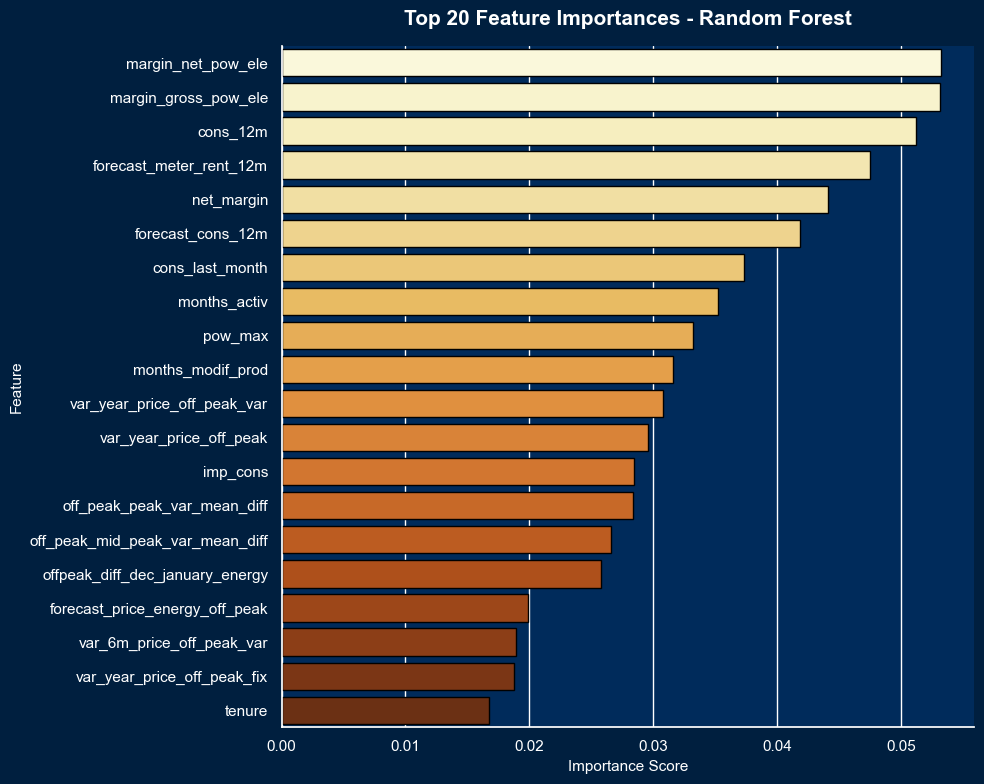

In [24]:
fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor('#001F3F')
ax.set_facecolor('#002B5B')

top_features = feature_importances.head(20)

sns.barplot(
    data=top_features,
    x='importance',
    y='feature',
    hue='feature',
    palette='YlOrBr',
    edgecolor='black',
    legend=False,
    ax=ax
)

ax.set_title('Top 20 Feature Importances - Random Forest',
             fontsize=15, fontweight='bold', color='white', pad=15)
ax.set_xlabel('Importance Score', color='white', fontsize=11)
ax.set_ylabel('Feature', color='white', fontsize=11)
ax.tick_params(colors='white')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_color('white')
ax.spines['left'].set_color('white')

plt.tight_layout()
plt.show()

The feature importance plot reveals that consumption and financial margin 
variables are the strongest predictors of churn.

`cons_12m`, `forecast_cons_12m`, and `cons_last_month` are among the top 
predictors. Annual and monthly consumption figures carry strong signal, 
suggesting that customers with distinct consumption patterns are more 
identifiable as churn risks.

`net_margin`, `margin_net_pow_ele`, and `margin_gross_pow_ele` feature 
prominently, suggesting that the financial relationship between PowerCo 
and the customer influences churn behaviour.

`months_activ` also appears in the top features, consistent with our EDA 
finding that newer customers churn at higher rates.

Notably, while the engineered price features do appear in the top 20, 
they are not the dominant signal. This partially challenges the original 
business hypothesis that price sensitivity is the primary driver of churn, 
suggesting the relationship between pricing and churn is more complex than 
initially assumed.